# Exploração da base — ERAMIA-RS 2026

Olho o treino antes de falar de modelo. O arquivo oficial não está no git: no Colab, a célula seguinte pede o upload de `final_treino_val.csv`. Localmente ele fica em `data/`.

Nada aqui é a AUC do ranking. É descrição. O modelo e o limiar estão no notebook `02_modelo.ipynb` e no README.


In [1]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not Path("src/desfecho").exists():
    subprocess.check_call(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/pedroohaubert/hospital-mortality-prediction.git",
            "hospital-mortality-prediction",
        ]
    )
    os.chdir("hospital-mortality-prediction")

ROOT = Path.cwd().resolve()
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

if IN_COLAB:
    subprocess.check_call(
        [
            sys.executable, "-m", "pip", "install", "-q",
            "catboost==1.2.10",
            "scikit-learn==1.9.1",
            "pandas==3.1.1",
            "numpy==2.5.4",
            "scipy==1.18.1",
            "matplotlib==3.11.2",
            "joblib==1.6.0",
        ]
    )

DATA = ROOT / "data" / "final_treino_val.csv"
if not DATA.exists():
    if not IN_COLAB:
        raise SystemExit("Coloque o CSV em data/final_treino_val.csv. Ele não vem no git.")
    from google.colab import files
    print("Envie o final_treino_val.csv")
    uploaded = files.upload()
    DATA.parent.mkdir(parents=True, exist_ok=True)
    name = next(iter(uploaded))
    DATA.write_bytes(uploaded[name])
print("raiz", ROOT)
print("dados", DATA, "existe" if DATA.exists() else "ausente")


raiz /workspace
dados /workspace/data/final_treino_val.csv existe


## O que tem em cada linha

6.332 internações, um identificador, 26 preditoras e o desfecho (1 óbito, 0 cura). Não há ausente neste arquivo. A idade é a coluna que mais separa. As duas nominais não devem ser lidas como número: `sociodemografico4` tem 27 níveis e `sociodemografico5` tem 5.


In [2]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

from desfecho.data import dataset_checks, load_table
from desfecho.schema import AGE_COL, CAT_COLS, ID_COL, TARGET_COL

df = load_table(DATA, require_target=True)
checks = dataset_checks(df)
print(f"linhas {checks['n']}")
print(f"óbitos {checks['obitos']}  prevalência {checks['prevalencia_obito']:.3f}")
print(f"idade {checks['idade_min']:.0f} a {checks['idade_max']:.0f}")
print(f"ausentes {checks['ausentes_preditores']}  ID duplicado {checks['id_duplicado']}")
print(f"níveis de {CAT_COLS[0]}: {checks['niveis_sociodemografico4']}")
print(f"níveis de {CAT_COLS[1]}: {checks['niveis_sociodemografico5']}")
print(f"AUC do ID numérico (só checagem, não entra no modelo): {checks['auc_id_numerico']:.3f}")
age_auc = roc_auc_score(df[TARGET_COL], pd.to_numeric(df[AGE_COL]))
print(f"AUC da idade crua, na amostra inteira: {age_auc:.3f}")
display(df.head(3))


linhas 6332
óbitos 3624  prevalência 0.572
idade 0 a 102
ausentes 0  ID duplicado 0
níveis de sociodemografico4: 27
níveis de sociodemografico5: 5
AUC do ID numérico (só checagem, não entra no modelo): 0.508
AUC da idade crua, na amostra inteira: 0.718


,ID,dadoclin1,dadoclin2,dadoclin3,dadoclin4,dadoclin5,dadoclin6,dadoclin7,dadoclin8,dadoclin9,...,sociodemografico4,sociodemografico5,comorbidade1,comorbidade2,comorbidade3,comorbidade4,comorbidade5,comorbidade6,comorbidade7,DESFECHO
0,A608287,1,0,1,0,0,1,0,0,0,...,26,4,0,0,0,0,0,0,0,1
1,A836141,1,0,0,0,0,1,1,1,0,...,26,1,0,0,0,0,1,0,0,0
2,A244981,1,0,1,0,0,1,0,0,0,...,23,1,0,0,0,0,1,0,0,0


A AUC da idade nesta célula usa a amostra inteira, sem validação. Serve para ver a ordem de grandeza. A AUC que eu cito no README é outra: média out-of-fold, com o modelo inteiro.

O ID perto de 0,50 é o que eu queria ver. Se o identificador previsse óbito, ele estaria carregando tempo ou serviço, e mesmo assim ficaria de fora.


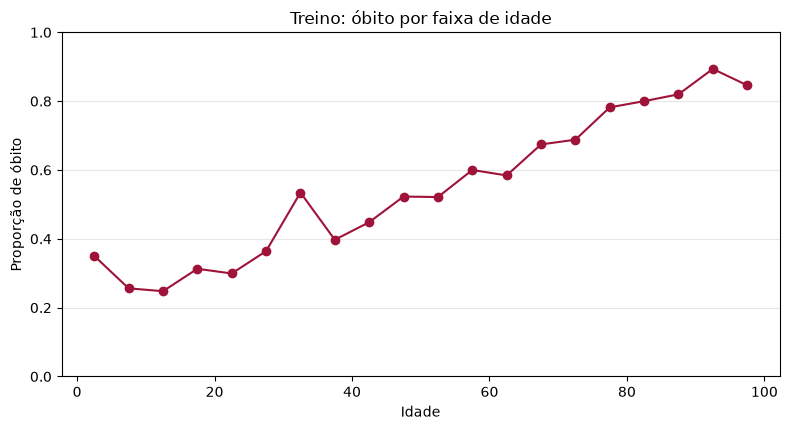

contagem por faixa
faixa
[0, 5)       197
[5, 10)      203
[10, 15)     230
[15, 20)     246
[20, 25)     274
[25, 30)     280
[30, 35)     290
[35, 40)     292
[40, 45)     319
[45, 50)     306
[50, 55)     328
[55, 60)     350
[60, 65)     380
[65, 70)     482
[70, 75)     545
[75, 80)     500
[80, 85)     490
[85, 90)     372
[90, 95)     188
[95, 100)     52


In [3]:
import matplotlib.pyplot as plt

age = pd.to_numeric(df[AGE_COL])
y = df[TARGET_COL].to_numpy()
bins = list(range(0, 105, 5))
cut = pd.cut(age, bins=bins, right=False)
table = pd.DataFrame({"faixa": cut, "y": y}).dropna().groupby("faixa", observed=True)["y"].agg(["mean", "count"])
centers = [(interval.left + interval.right) / 2 for interval in table.index]

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(centers, table["mean"], marker="o", color="#9f1239")
ax.set_ylim(0, 1)
ax.set_xlabel("Idade")
ax.set_ylabel("Proporção de óbito")
ax.set_title("Treino: óbito por faixa de idade")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
display(fig)
plt.close(fig)

print("contagem por faixa")
print(table["count"].to_string())


A mortalidade sobe com a idade e não é uma reta perfeita. Por isso a logística do modelo usa spline, não a idade crua. Há um solavanco perto dos 30 anos. Sem o dicionário confirmado eu não dou nome a isso.

`sociodemografico4` e `sociodemografico5` ficam como categoria. O código 26 é o mais comum na primeira; o código 1 é o mais comum na segunda. A hipótese de que a segunda é raça/cor com maioria parda (código 4 no SIVEP) não fecha neste arquivo. A fonte oficial ainda não foi dita. Trato os nomes como estão.


In [4]:
for col in CAT_COLS:
    counts = df[col].value_counts()
    order = sorted(counts.index, key=lambda value: float(value))
    counts = counts.loc[order]
    print(col)
    print(counts.to_string())
    print()


sociodemografico4
sociodemografico4
1       16
2       30
3       43
4        6
5      197
6       69
7      197
8      126
9      519
10      41
11     745
12     100
13     134
14      40
15       8
16      16
17      67
18     764
19     199
20      43
21      30
22       4
23     306
24     456
25      34
26    2122
27      20

sociodemografico5
sociodemografico5
1    3708
2     307
3      80
4    2211
5      26

